HEART DISEASE RISK CLASSIFICATION

In [1]:
# Heart Disease Risk Classification
# Team: Monisha and Tanya

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")
print("scikit-learn version:", sklearn.__version__)


Libraries imported successfully!
scikit-learn version: 1.7.2


1. DATASET LOADING

In [2]:
# Install the UCI dataset package
!pip -q install ucimlrepo

# Fetch the official UCI Heart Disease dataset
from ucimlrepo import fetch_ucirepo

heart_disease = fetch_ucirepo(id=45)

# Separate input features and target
X = heart_disease.data.features
y = heart_disease.data.targets

# Combine them into one DataFrame
df = X.copy()
df["num"] = y["num"]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


2. INITIAL DATASET INSPECTION

In [3]:
# Check column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["num"].value_counts().sort_index())


Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB

Missing values in each column:
age         0
sex         0
cp 

3. EXPLORATORY DATA ANALYSIS

Duplicate rows: 0


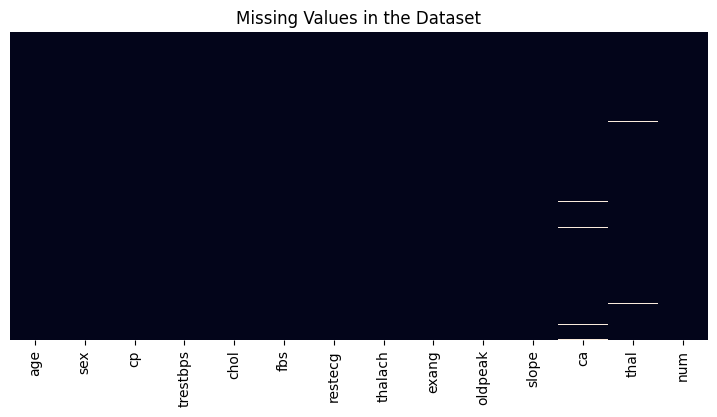


Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64


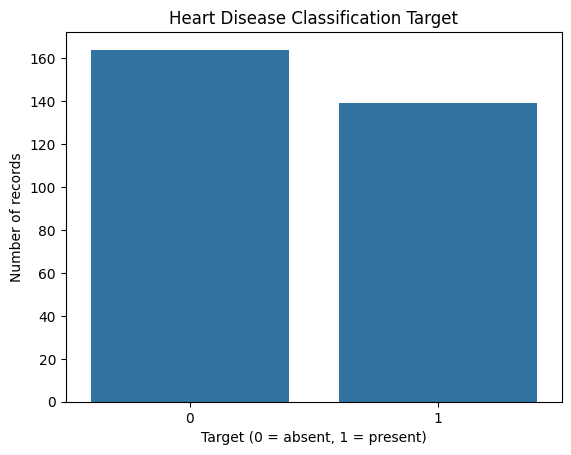

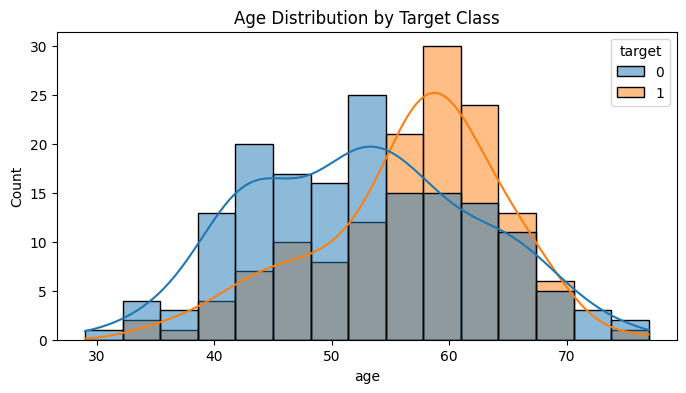

In [4]:
# 1. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 2. Visualize missing values
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in the Dataset")
plt.show()

# 3. Create binary target
df["target"] = (df["num"] > 0).astype(int)

print("\nBinary target distribution:")
print(df["target"].value_counts())

# 4. Visualize target distribution
sns.countplot(data=df, x="target")
plt.title("Heart Disease Classification Target")
plt.xlabel("Target (0 = absent, 1 = present)")
plt.ylabel("Number of records")
plt.show()

# 5. Explore age distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="age", hue="target",
             bins=15, kde=True, multiple="layer")
plt.title("Age Distribution by Target Class")
plt.show()


In [5]:
# Summary statistics
print("Dataset summary:")
display(df.describe().round(2))

# Average age by target class
print("\nAverage age by target:")
display(df.groupby("target")["age"].agg(["mean", "median", "min", "max"]).round(2))

# Missing values
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))


Dataset summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94,0.46
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00,1.00



Average age by target:


,mean,median,min,max
target,,,,
0,52.59,52.0,29,76
1,56.63,58.0,35,77



Missing values:


,Missing Count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


4. DATA PREPROCESSING & TRAIN-TEST SPLIT

In [ ]:
from sklearn.model_selection import train_test_split

# Input features: exclude both original and derived targets
X = df.drop(columns=["num", "target"])

# Target variable
y = df["target"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training class distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing class distribution:
target
0    33
1    28
Name: count, dtype: int64
Training features: (242, 13)
Testing features: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64

Testing target distribution:
target
0    33
1    28
Name: count, dtype: int64


5. LOGISTIC REGRESSION

In [14]:
# Logistic Regression: Training and Evaluation

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Create the preprocessing and modelling pipeline
log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# 2. Train the model
log_model.fit(X_train, y_train)

# 3. Generate predictions
log_pred = log_model.predict(X_test)

# 4. Evaluate the model
print("Logistic Regression trained successfully!")
print(f"Accuracy:  {accuracy_score(y_test, log_pred):.3f}")
print(f"Precision: {precision_score(y_test, log_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, log_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, log_pred, zero_division=0):.3f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    log_pred,
    target_names=["No disease detected", "Disease present"],
    zero_division=0
))


Logistic Regression trained successfully!
Accuracy:  0.869
Precision: 0.812
Recall:    0.929
F1-score:  0.867

Classification Report:
                     precision    recall  f1-score   support

No disease detected       0.93      0.82      0.87        33
    Disease present       0.81      0.93      0.87        28

           accuracy                           0.87        61
          macro avg       0.87      0.87      0.87        61
       weighted avg       0.88      0.87      0.87        61



6. RANDOM FOREST

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall:", round(recall_score(y_test, rf_pred), 3))
print("F1-score:", round(f1_score(y_test, rf_pred), 3))


Random Forest Results
---------------------
Accuracy: 0.918
Precision: 0.871
Recall: 0.964
F1-score: 0.915


7. MODEL PERFORMANCE COMPARISON

In [16]:
# Compare Logistic Regression and Random Forest

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, log_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, log_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, log_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ]
})

display(results.round(3))


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.869,0.812,0.929,0.867
1,Random Forest,0.918,0.871,0.964,0.915


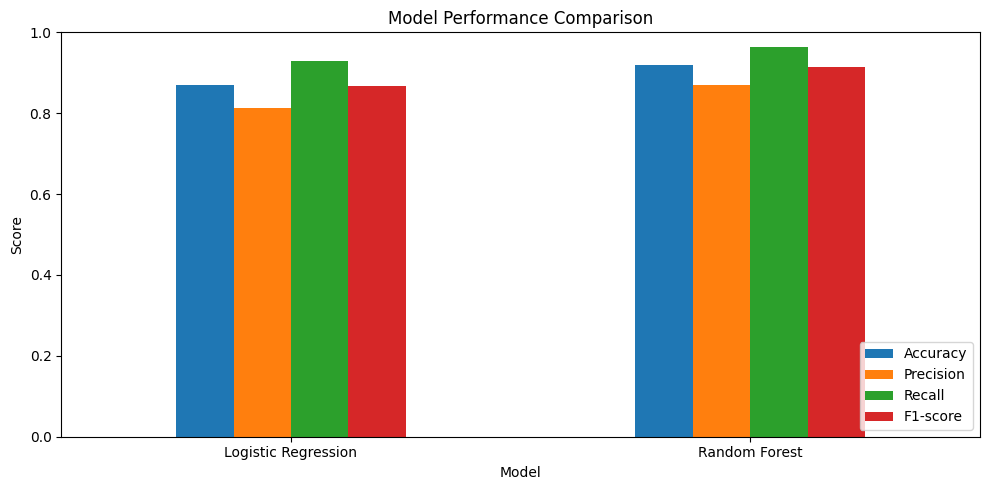

In [17]:
results_plot = results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

results_plot.plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


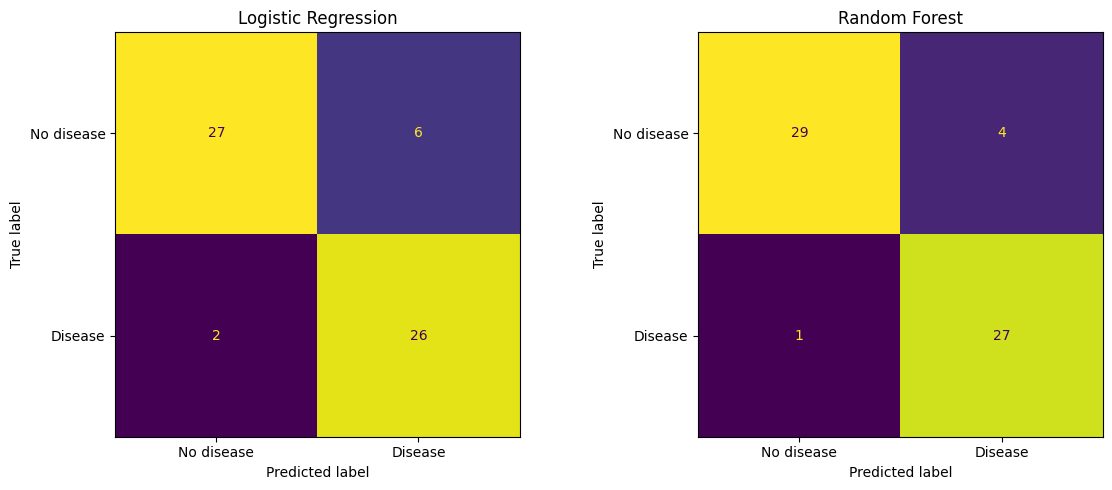

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    log_pred,
    display_labels=["No disease", "Disease"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Logistic Regression")

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No disease", "Disease"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

## Conclusion

In this project, we developed and compared two machine learning classification models, Logistic Regression and Random Forest, using the UCI Heart Disease dataset.

The dataset was explored to understand its structure, missing values, target distribution, and age patterns. Missing values were handled using median imputation, and the dataset was divided into training and testing sets using an 80:20 stratified split.

Logistic Regression achieved an accuracy of 86.9%, while Random Forest achieved an accuracy of 91.8% on the test set. Random Forest also achieved higher precision, recall, and F1-score in this evaluation.

Based on these results, Random Forest performed better on this particular test set. However, the dataset is relatively small, and the models were evaluated on a single train-test split. Further testing and validation would be required to assess how well the models generalize.

**Disclaimer:** This project is for educational purposes only. The model is not clinically validated and must not be used for medical diagnosis or treatment decisions.

## Future Improvements

- **Cross-validation:** Evaluate the models across multiple data splits for more reliable performance estimates.
- **Hyperparameter tuning:** Optimize the Random Forest and Logistic Regression settings to explore whether performance can be improved.
- **Additional evaluation metrics:** Examine ROC-AUC and other relevant metrics to better understand classification performance.
- **Larger independent datasets:** Evaluate the models on additional data to assess generalization.
- **Feature analysis:** Investigate which input features contribute most to the models' predictions.
- **Responsible use:** Ensure that any future clinical application undergoes rigorous validation and appropriate medical oversight.